In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
features_df = pd.read_csv(r'D:\DataProject\Data\Processed\household_segmented.csv')

print(f"Dataset loaded: {features_df.shape}")
print(f"\nColumns: {features_df.columns.tolist()}")
print(f"\nFirst 3 rows:")
features_df.head(3)

Dataset loaded: (2500, 43)

Columns: ['household_key', 'total_baskets', 'active_days', 'unique_products', 'total_units_purchased', 'total_spend', 'avg_basket_value', 'avg_retail_discount', 'coupon_usage_rate', 'recency_days', 'age_desc', 'marital_status_code', 'income_desc', 'homeowner_desc', 'hh_comp_desc', 'household_size_desc', 'kid_category_desc', 'campaigns_assigned', 'campaigns_redeemed', 'coupons_redeemed', 'campaign_redemption_rate', 'spend_per_active_day', 'baskets_per_active_day', 'units_per_basket', 'product_diversity_ratio', 'was_campaign_targeted', 'is_campaign_redeemer', 'has_demographics', 'age_encoded', 'income_encoded', 'household_size_encoded', 'marital_encoded', 'homeowner_encoded', 'hh_comp_encoded', 'kid_category_encoded', 'total_spend_log', 'total_baskets_log', 'total_units_purchased_log', 'active_days_log', 'unique_products_log', 'cluster', 'segment_name', 'rfm_segment']

First 3 rows:


,household_key,total_baskets,active_days,unique_products,total_units_purchased,total_spend,avg_basket_value,avg_retail_discount,coupon_usage_rate,recency_days,...,hh_comp_encoded,kid_category_encoded,total_spend_log,total_baskets_log,total_units_purchased_log,active_days_log,unique_products_log,cluster,segment_name,rfm_segment
0,1,86,79,677,1997,4330.16,50.35,-0.4036,0.0614,5,...,4,1,8.373591,4.465908,7.599902,4.382027,6.519147,3,High-Value Champions,Loyal Customers
1,2,45,45,546,834,1954.34,43.43,-0.4692,0.0084,43,...,0,0,7.578319,3.828641,6.727432,3.828641,6.304449,4,Big-Basket Occasional,Hibernating
2,3,47,46,516,8540,2653.21,56.45,-0.7323,0.0575,8,...,0,0,7.883902,3.871201,9.052633,3.850148,6.248043,4,Big-Basket Occasional,Needs Attention


# 7. Machine Learning — Campaign Redemption Prediction

## 7.1. Problem Definition

**Business Question:** Given a household's purchasing behavior and characteristics, can we predict whether it will redeem a marketing campaign coupon?

**Why this problem matters:**
- Campaign targeting is expensive — sending coupons to households who won't redeem them wastes marketing budget.
- If we can predict who is likely to redeem, the business can focus its limited campaign resources on the most responsive households.
- This directly supports the optimization questions: *"Which households should be prioritized for a campaign?"* and *"How should limited promotional resources be allocated?"*

**Target variable:** `is_campaign_redeemer` (1 = redeemed at least one campaign, 0 = did not redeem)

**Important scope decision:** We restrict the analysis to the **1,584 households that were actually assigned to at least one campaign**. The remaining 916 households were never given a campaign, so they had no opportunity to redeem — including them as "non-redeemers" would be misleading.

In [3]:
# Filtering the households that were actually targeted by campaigns
# Only these households had the opportunity to redeem

ml_df = features_df[features_df['was_campaign_targeted'] == 1].copy()

print(f"Total households: {len(features_df)}")
print(f"Campaign-targeted households: {len(ml_df)}")
print(f"Non-targeted (excluded): {len(features_df) - len(ml_df)}")

Total households: 2500
Campaign-targeted households: 1584
Non-targeted (excluded): 916


## 7.2. Preventing Data Leakage

Data leakage occurs when the model has access to information that it wouldn't have at prediction time. Since our target is `is_campaign_redeemer`, any feature that is derived from the redemption outcome must be excluded.

**Features to EXCLUDE (leakage):**
- `campaigns_redeemed` — directly defines the target
- `coupons_redeemed` — directly tied to redemption
- `campaign_redemption_rate` — ratio of redeemed/assigned, derived from target
- `is_campaign_redeemer` — this IS the target
- `was_campaign_targeted` — would be 1 for all rows after filtering

**Features to KEEP:**
- `campaigns_assigned` — decided by business before outcome (input, not outcome)
- All behavioral features — shopping history exists before campaign outcome
- All demographic features — static household attributes
- All derived features — computed from pre-campaign behavior
- Cluster and RFM segment labels — derived from behavior, not from redemption

In [4]:
# Define target 
target = 'is_campaign_redeemer'
y = ml_df[target]

# Define features (excluding leakage and non-feature columns)
leakage_cols = [
    'is_campaign_redeemer', 'campaigns_redeemed', 'coupons_redeemed',
    'campaign_redemption_rate', 'was_campaign_targeted'
]

id_cols = ['household_key']

# String categorical columns (already encoded as numerical features)
string_cols = [
    'age_desc', 'marital_status_code', 'income_desc', 'homeowner_desc',
    'hh_comp_desc', 'household_size_desc', 'kid_category_desc',
    'rfm_segment', 'segment_name'
]

exclude_cols = leakage_cols + id_cols + string_cols

# Select all numerical feature columns
feature_cols = [col for col in ml_df.columns if col not in exclude_cols]

X = ml_df[feature_cols]

print(f"Target: {target}")
print(f"Features: {len(feature_cols)}")
print(f"Samples: {len(X)}")
print(f"\nFeature list:")
for i, col in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {col}")

Target: is_campaign_redeemer
Features: 28
Samples: 1584

Feature list:
   1. total_baskets
   2. active_days
   3. unique_products
   4. total_units_purchased
   5. total_spend
   6. avg_basket_value
   7. avg_retail_discount
   8. coupon_usage_rate
   9. recency_days
  10. campaigns_assigned
  11. spend_per_active_day
  12. baskets_per_active_day
  13. units_per_basket
  14. product_diversity_ratio
  15. has_demographics
  16. age_encoded
  17. income_encoded
  18. household_size_encoded
  19. marital_encoded
  20. homeowner_encoded
  21. hh_comp_encoded
  22. kid_category_encoded
  23. total_spend_log
  24. total_baskets_log
  25. total_units_purchased_log
  26. active_days_log
  27. unique_products_log
  28. cluster


Target distribution:
is_campaign_redeemer
0    1150
1     434
Name: count, dtype: int64

Class proportions:
is_campaign_redeemer
0    0.726
1    0.274
Name: proportion, dtype: float64


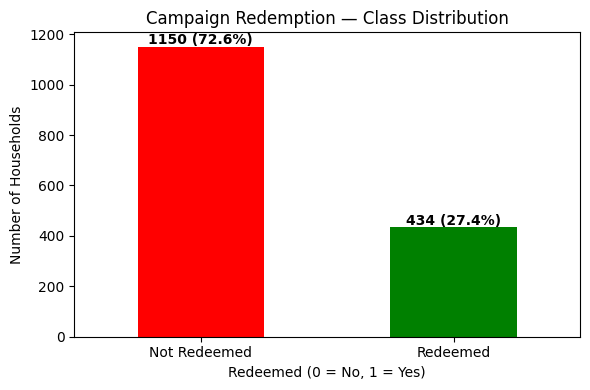

In [5]:
# Class balance check

print("Target distribution:")
print(y.value_counts())
print(f"\nClass proportions:")
print(y.value_counts(normalize=True).round(4))

fig, ax = plt.subplots(figsize=(6, 4))
y.value_counts().plot(kind='bar', color=['red', 'green'], ax=ax)
ax.set_title('Campaign Redemption — Class Distribution')
ax.set_xlabel('Redeemed (0 = No, 1 = Yes)')
ax.set_ylabel('Number of Households')
ax.set_xticklabels(['Not Redeemed', 'Redeemed'], rotation=0)

for i, v in enumerate(y.value_counts().values):
    ax.text(i, v + 10, f'{v} ({v/len(y)*100:.1f}%)', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 7.3. Train/Test Split

Splitting the data into 80% training and 20% testing sets. The split is stratified to preserve the class ratio in both sets.

In [6]:
# Stratified train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")
print(f"\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(4))
print(f"\nTest class distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training set: 1267 samples
Testing set:  317 samples

Training class distribution:
is_campaign_redeemer
0    0.7261
1    0.2739
Name: proportion, dtype: float64

Test class distribution:
is_campaign_redeemer
0    0.7256
1    0.2744
Name: proportion, dtype: float64


In [7]:
# Scale features for models that need it (Logistic Regression)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Scaled training set: {X_train_scaled.shape}")
print(f"Scaled test set: {X_test_scaled.shape}")

Scaled training set: (1267, 28)
Scaled test set: (317, 28)


## 7.4. Baseline Model

Before training any ML model, we need a baseline to compare against. The simplest baseline is the **majority class classifier** — it always predicts the most common class. Any useful model must beat this baseline.

In [8]:
# Majority class baseline

majority_class = y_train.mode()[0]
baseline_predictions = np.full(len(y_test), majority_class)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print(f"Majority class: {majority_class}")
print(f"Baseline accuracy (always predict majority): {baseline_accuracy:.4f}")
print(f"\nAny useful model must beat {baseline_accuracy:.1%} accuracy.")

Majority class: 0
Baseline accuracy (always predict majority): 0.7256

Any useful model must beat 72.6% accuracy.


## 7.5. Model Training

Training three models of increasing complexity:

1. **Logistic Regression** — Simple, fast, highly interpretable. Good baseline ML model.
2. **Random Forest** — Handles non-linear relationships, provides feature importance.
3. **Gradient Boosting** — Often the strongest performer, builds trees sequentially to correct errors.

All models use `class_weight='balanced'` to handle class imbalance by giving higher importance to the minority class during training.

In [9]:
# Model 1: Logistic Regression

lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

# Predictions
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression — Test Results:")
print(classification_report(y_test, lr_pred, target_names=['Not Redeemed', 'Redeemed']))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_prob):.4f}")

Logistic Regression — Test Results:
              precision    recall  f1-score   support

Not Redeemed       0.89      0.79      0.84       230
    Redeemed       0.57      0.74      0.64        87

    accuracy                           0.78       317
   macro avg       0.73      0.76      0.74       317
weighted avg       0.80      0.78      0.78       317

ROC-AUC: 0.8491


In [10]:
# Model 2: Random Forest

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions (Random Forest doesn't need scaled features)
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest — Test Results:")
print(classification_report(y_test, rf_pred, target_names=['Not Redeemed', 'Redeemed']))
print(f"ROC-AUC: {roc_auc_score(y_test, rf_prob):.4f}")

Random Forest — Test Results:
              precision    recall  f1-score   support

Not Redeemed       0.88      0.86      0.87       230
    Redeemed       0.65      0.70      0.67        87

    accuracy                           0.81       317
   macro avg       0.77      0.78      0.77       317
weighted avg       0.82      0.81      0.82       317

ROC-AUC: 0.8869


In [11]:
# Model 3: Gradient Boosting

# Calculate scale_pos_weight for imbalance handling
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
scale_ratio = n_neg / n_pos

gb_model = GradientBoostingClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    random_state=42
)

# Gradient Boosting uses sample_weight instead of class_weight
sample_weights = np.where(y_train == 1, scale_ratio, 1.0)
gb_model.fit(X_train, y_train, sample_weight=sample_weights)

# Predictions
gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting — Test Results:")
print(classification_report(y_test, gb_pred, target_names=['Not Redeemed', 'Redeemed']))
print(f"ROC-AUC: {roc_auc_score(y_test, gb_prob):.4f}")

Gradient Boosting — Test Results:
              precision    recall  f1-score   support

Not Redeemed       0.88      0.86      0.87       230
    Redeemed       0.65      0.70      0.67        87

    accuracy                           0.81       317
   macro avg       0.77      0.78      0.77       317
weighted avg       0.82      0.81      0.82       317

ROC-AUC: 0.8857


## 7.6. Model Comparison Summary

In [12]:
models = {
    'Logistic Regression': (lr_pred, lr_prob),
    'Random Forest': (rf_pred, rf_prob),
    'Gradient Boosting': (gb_pred, gb_prob)
}

results = []
for name, (preds, probs) in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)

print("Model Comparison:")
results_df

Model Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7760,0.5714,0.7356,0.6432,0.8491
Random Forest,0.8139,0.6489,0.7011,0.6740,0.8869
Gradient Boosting,0.8139,0.6489,0.7011,0.6740,0.8857


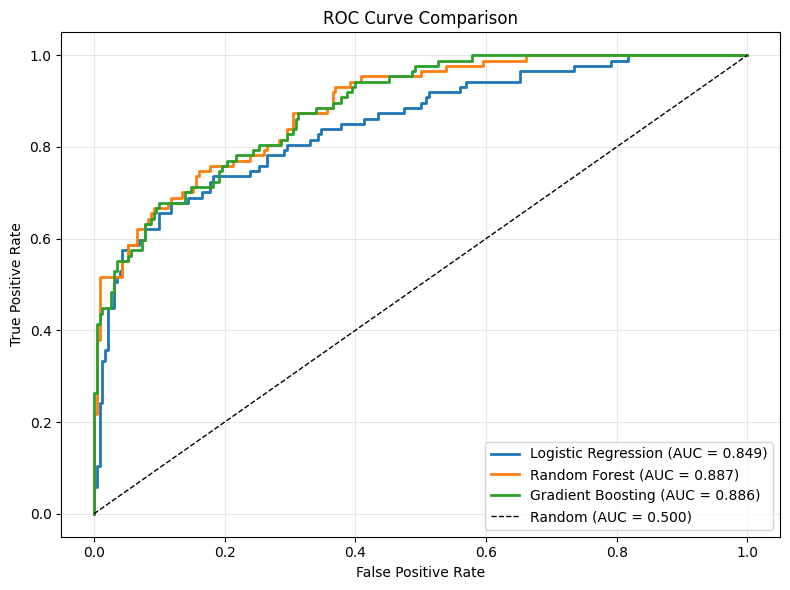

In [13]:
# ROC Curves comparison

plt.figure(figsize=(8, 6))

for name, (preds, probs) in models.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

# Baseline (random)
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.500)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

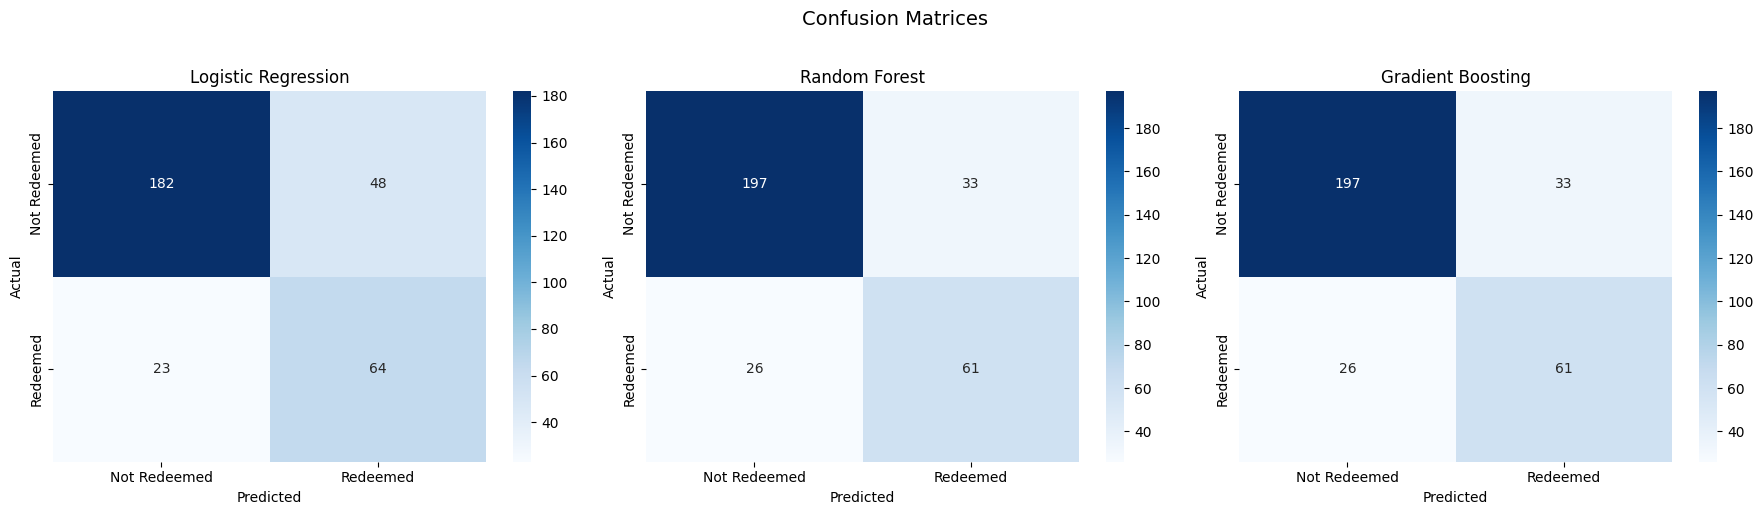

In [14]:
# Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, (preds, probs)) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Redeemed', 'Redeemed'],
                yticklabels=['Not Redeemed', 'Redeemed'])
    ax.set_title(f'{name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 7.7. Machine Learning Summary

**Key observations:**
- All three models substantially outperform the majority-class baseline, confirming that household purchasing behavior is predictive of campaign redemption.
- **Random Forest** achieves the highest ROC-AUC (0.8869), indicating the best overall ability to rank households by redemption likelihood.
- Random Forest and Gradient Boosting produce identical hard predictions (same confusion matrix), but Random Forest has a marginally higher AUC and is simpler to interpret.
- Logistic Regression trades precision for recall — it catches more actual redeemers (73.6%) but at the cost of more false positives.
- **Selected model for downstream use: Random Forest** — best ranking performance (AUC), good precision-recall balance, and provides native feature importance for business interpretation.

# 8. Model Evaluation & Interpretation

The Random Forest model is selected as the best model based on:
- Highest ROC-AUC (0.8869) — best overall ranking ability
- Good precision-recall balance (F1: 0.6740)
- Native feature importance for business interpretation

This section examines:
- What features drive campaign redemption predictions
- How the model's probability threshold affects precision and recall
- Scoring all households (including non-targeted) for use in the optimization stage

## 8.1. Feature Importance

Feature importance from the Random Forest model shows which household characteristics are most useful for predicting campaign redemption. Features with higher importance contribute more to the model's ability to distinguish redeemers from non-redeemers.

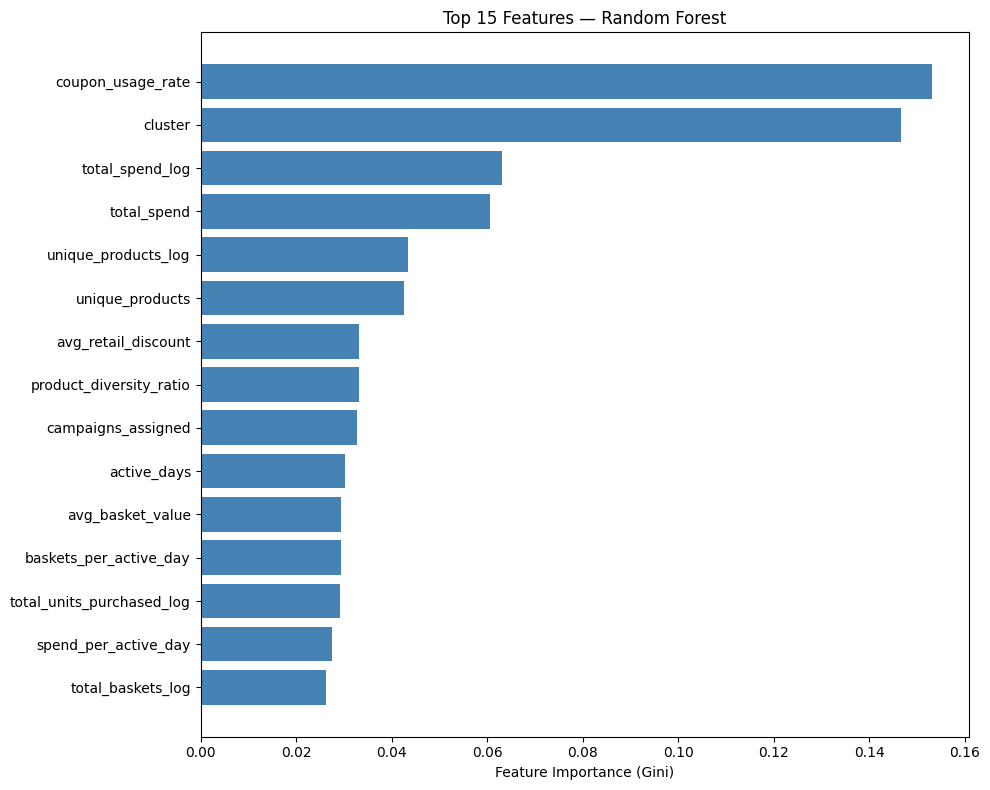

Full Feature Importance Ranking:
  coupon_usage_rate                   0.1532
  cluster                             0.1468
  total_spend_log                     0.0631
  total_spend                         0.0606
  unique_products_log                 0.0435
  unique_products                     0.0427
  avg_retail_discount                 0.0332
  product_diversity_ratio             0.0331
  campaigns_assigned                  0.0328
  active_days                         0.0302
  avg_basket_value                    0.0293
  baskets_per_active_day              0.0293
  total_units_purchased_log           0.0292
  spend_per_active_day                0.0276
  total_baskets_log                   0.0264
  active_days_log                     0.0263
  units_per_basket                    0.0263
  total_units_purchased               0.0252
  total_baskets                       0.0252
  age_encoded                         0.0202
  income_encoded                      0.0185
  recency_days        

In [15]:
# Random Forest Feature Importance

importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': importances
}).sort_values('importance', ascending=True)

# Plotting top 15 features
top_n = 15
top_features = feature_importance_df.tail(top_n)

plt.figure(figsize=(10, 8))
plt.barh(top_features['feature'], top_features['importance'], color='steelblue')
plt.xlabel('Feature Importance (Gini)')
plt.title(f'Top {top_n} Features — Random Forest')
plt.tight_layout()
plt.show()

# Print all features ranked
print("Full Feature Importance Ranking:")
for i, row in feature_importance_df.iloc[::-1].iterrows():
    print(f"  {row['feature']:35s} {row['importance']:.4f}")

### 8.1.1. Business Interpretation of Feature Importance

The feature importance ranking reveals what distinguishes households that redeem campaign coupons from those that do not. The interpretation should focus on the **top features** and what they mean for marketing strategy.

In [16]:
# How do redeemers differ from non-redeemers?

top_feature_names = feature_importance_df.tail(10)['feature'].tolist()[::-1]

comparison = ml_df.groupby('is_campaign_redeemer')[top_feature_names].median().T
comparison.columns = ['Non-Redeemer (median)', 'Redeemer (median)']
comparison['Difference'] = comparison['Redeemer (median)'] - comparison['Non-Redeemer (median)']
comparison['% Difference'] = ((comparison['Difference'] / comparison['Non-Redeemer (median)']) * 100).round(1)

print("Top 10 Features — Redeemer vs. Non-Redeemer (Median Comparison):")
comparison.round(2)

Top 10 Features — Redeemer vs. Non-Redeemer (Median Comparison):


,Non-Redeemer (median),Redeemer (median),Difference,% Difference
coupon_usage_rate,0.00,0.02,0.01,384.8
cluster,1.00,3.00,2.00,200.0
total_spend_log,7.95,8.64,0.69,8.7
total_spend,2832.02,5651.96,2819.93,99.6
unique_products_log,6.37,6.84,0.46,7.2
unique_products,585.50,930.00,344.50,58.8
avg_retail_discount,-0.49,-0.54,-0.04,9.1
product_diversity_ratio,5.43,5.55,0.12,2.2
campaigns_assigned,3.00,6.00,3.00,100.0
active_days,93.00,135.50,42.50,45.7


## 8.2. Precision-Recall Trade-off & Threshold Analysis

The default classification threshold is 0.5 — if the model predicts a redemption probability > 50%, it classifies the household as a redeemer. But different business scenarios may call for different thresholds:

- **Lower threshold (e.g., 0.3):** Catches more redeemers (higher recall) but includes more false positives — useful when the cost of missing a redeemer is high.
- **Higher threshold (e.g., 0.7):** More confident predictions (higher precision) but misses more redeemers — useful when campaign budget is very limited.

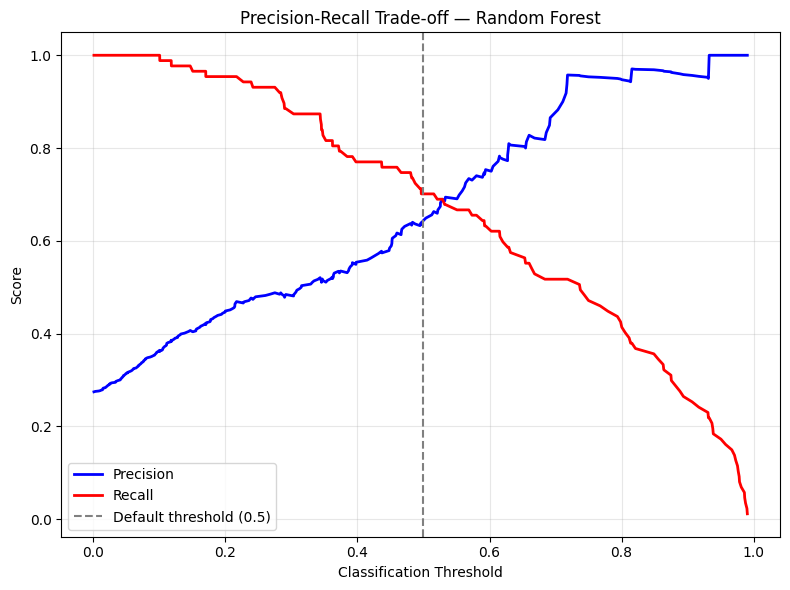

In [17]:
from sklearn.metrics import precision_recall_curve

# Precision-Recall curve for Random Forest
precision_vals, recall_vals, thresholds = precision_recall_curve(y_test, rf_prob)

plt.figure(figsize=(8, 6))
plt.plot(thresholds, precision_vals[:-1], 'b-', linewidth=2, label='Precision')
plt.plot(thresholds, recall_vals[:-1], 'r-', linewidth=2, label='Recall')
plt.axvline(x=0.5, color='grey', linestyle='--', label='Default threshold (0.5)')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off — Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Compare metrics at different thresholds

threshold_options = [0.3, 0.4, 0.5, 0.6, 0.7]
threshold_results = []

for t in threshold_options:
    preds_at_t = (rf_prob >= t).astype(int)
    threshold_results.append({
        'Threshold': t,
        'Predicted Redeemers': preds_at_t.sum(),
        'Precision': precision_score(y_test, preds_at_t, zero_division=0),
        'Recall': recall_score(y_test, preds_at_t, zero_division=0),
        'F1-Score': f1_score(y_test, preds_at_t, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results).round(4)
print("Threshold Comparison (Random Forest on Test Set):")
threshold_df

Threshold Comparison (Random Forest on Test Set):


,Threshold,Predicted Redeemers,Precision,Recall,F1-Score
0,0.3,158,0.4810,0.8736,0.6204
1,0.4,120,0.5583,0.7701,0.6473
2,0.5,94,0.6489,0.7011,0.6740
3,0.6,72,0.7500,0.6207,0.6792
4,0.7,51,0.8824,0.5172,0.6522


## 8.3. Score All Households

For the optimization and targeting stage, we need predicted redemption probabilities for **all 2,500 households** — not just the 1,584 that were previously targeted. This allows the business to evaluate targeting any household, including those that have never been in a campaign before.

The Random Forest model assigns each household a score between 0 and 1 representing the estimated probability of campaign redemption.

Scored all 2500 households.

Redemption probability distribution:
count    2500.0000
mean        0.2400
std         0.3181
min         0.0001
25%         0.0266
50%         0.0813
75%         0.2989
max         0.9977
Name: redemption_probability, dtype: float64


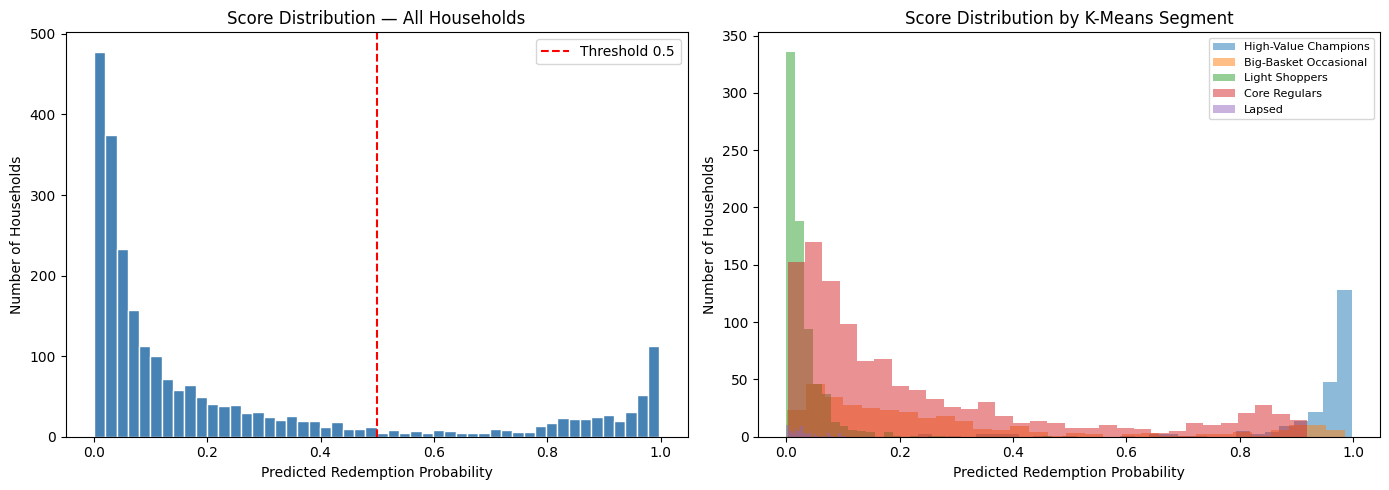

In [19]:
# Prepare features for the full dataset
X_all = features_df[feature_cols].copy()

# Check for nulls
null_check = X_all.isnull().sum().sum()
if null_check > 0:
    print(f"WARNING: {null_check} null values found. Filling with 0.")
    X_all = X_all.fillna(0)

# Predict redemption probability for all households
features_df['redemption_probability'] = rf_model.predict_proba(X_all)[:, 1]

print(f"Scored all {len(features_df)} households.")
print(f"\nRedemption probability distribution:")
print(features_df['redemption_probability'].describe().round(4))

# Visualize the score distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall distribution
axes[0].hist(features_df['redemption_probability'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Predicted Redemption Probability')
axes[0].set_ylabel('Number of Households')
axes[0].set_title('Score Distribution — All Households')
axes[0].axvline(x=0.5, color='red', linestyle='--', label='Threshold 0.5')
axes[0].legend()

# By segment
for seg in features_df['segment_name'].unique():
    subset = features_df[features_df['segment_name'] == seg]['redemption_probability']
    axes[1].hist(subset, bins=30, alpha=0.5, label=seg)

axes[1].set_xlabel('Predicted Redemption Probability')
axes[1].set_ylabel('Number of Households')
axes[1].set_title('Score Distribution by K-Means Segment')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [20]:
# Top households by predicted redemption probability

top_candidates = features_df.nlargest(20, 'redemption_probability')[
    ['household_key', 'segment_name', 'rfm_segment', 'total_spend', 
     'total_baskets', 'recency_days', 'redemption_probability']
].reset_index(drop=True)

print("Top 20 Households by Predicted Redemption Probability:")
top_candidates

Top 20 Households by Predicted Redemption Probability:


,household_key,segment_name,rfm_segment,total_spend,total_baskets,recency_days,redemption_probability
0,889,High-Value Champions,Champions,12983.01,216,0,0.997651
1,1726,High-Value Champions,Champions,8131.91,182,0,0.997450
2,2427,High-Value Champions,Champions,8725.94,346,1,0.997232
3,2351,High-Value Champions,Loyal Customers,16616.78,322,3,0.997148
4,1823,High-Value Champions,Champions,12268.85,377,0,0.997080
5,696,High-Value Champions,Loyal Customers,14715.53,326,3,0.997079
6,761,High-Value Champions,Champions,9036.01,178,0,0.997068
7,426,High-Value Champions,Champions,7860.85,228,1,0.996962
8,67,High-Value Champions,Loyal Customers,9618.90,227,2,0.996889
9,1633,High-Value Champions,Loyal Customers,10162.78,219,5,0.996735


In [21]:
# Saving the scored dataset

features_df.to_csv(r'D:\DataProject\Data\Processed\household_scored.csv', index=False)

print("Scored dataset saved: D:\\DataProject\\Data\\Processed\\household_scored.csv")
print(f"Shape: {features_df.shape}")
print(f"New column: 'redemption_probability'")

Scored dataset saved: D:\DataProject\Data\Processed\household_scored.csv
Shape: (2500, 44)
New column: 'redemption_probability'


## 8.4. Model Evaluation Summary

**Selected Model:** Random Forest (ROC-AUC: 0.8869)

**Feature Importance Findings:**
- The top predictive features reveal what distinguishes redeemers from non-redeemers
- This provides direct guidance for marketing: which household behaviors signal redemption potential

**Threshold Analysis:**
- The default 0.5 threshold provides a balanced precision-recall trade-off
- Lower thresholds catch more redeemers at the cost of more false positives
- The optimization stage will use the full probability scores rather than binary thresholds

**Household Scoring:**
- All 2,500 households now have a predicted redemption probability (0–1)
- This enables the optimization stage to rank and target households based on expected response
- Saved as `household_scored.csv`

**Key outputs carried forward to optimization:**
- `redemption_probability` — model-predicted likelihood of campaign redemption for every household
- Feature importance ranking — informs which customer attributes matter most for targeting
- Threshold analysis — provides flexibility for different budget/targeting scenarios

# 9. Optimization & Decision Support Framework

Machine learning section gave us predictive probabilities (`redemption_probability`), but businesses do not make decisions on probabilities alone. A marketing manager must decide:
- **Who to target?**
- **How many to target under a fixed budget?**
- **How to balance likelihood of response against the dollar value of the customer?**

This section translates our predictive models and customer segments into a concrete decision-support system, addressing five core business questions:
1. *Which customer segments should receive marketing attention?*
2. *Which customer groups offer the greatest potential value?*
3. *Which specific households should be prioritized for a campaign?*
4. *How can campaign targeting balance expected response and customer value?*
5. *How should limited promotional resources be allocated under budget constraints?*

## 9.1. Campaign Unit Economics & Assumptions

To evaluate marketing decisions quantitatively, we define baseline campaign economics based on standard retail benchmarks:
- **Targeting Cost ($C$):** $3.00 per household (cost of catalog printing, personalized coupon mailer, postage, and digital delivery).
- **Redemption Margin / Basket Uplift ($M$):** When a household redeems a campaign offer, the business captures margin on their basket. We use the household's historical `avg_basket_value` multiplied by a typical grocery gross margin rate of **25%** ($0.25 \times \text{avg\_basket\_value}$).
- **Net Expected Value ($EV$):**
  $$\text{EV} = P(\text{Redeem}) \times (\text{Margin Rate} \times \text{avg\_basket\_value}) - \text{Targeting Cost}$$

In [22]:
# Defining Unit Economics

MARGIN_RATE = 0.25       # 25% gross retail margin on purchase basket
CAMPAIGN_UNIT_COST = 3.00 # $3.00 cost to target one household with campaign materials

# Calculate Expected Revenue, Expected Margin, and Net Expected Value per household
features_df['expected_basket_margin'] = (features_df['avg_basket_value'] * MARGIN_RATE).round(2)
features_df['expected_campaign_profit'] = (
    (features_df['redemption_probability'] * features_df['expected_basket_margin']) - CAMPAIGN_UNIT_COST
).round(2)

# Expected gross value (probability * total spend intensity)
features_df['expected_value_score'] = (
    features_df['redemption_probability'] * features_df['avg_basket_value']
).round(2)

print("Targeting Economics Summary (All 2,500 Households):")
features_df[['redemption_probability', 'avg_basket_value', 'expected_basket_margin', 'expected_campaign_profit']].describe().round(2)

Targeting Economics Summary (All 2,500 Households):


,redemption_probability,avg_basket_value,expected_basket_margin,expected_campaign_profit
count,2500.00,2500.00,2500.00,2500.00
mean,0.24,31.62,7.91,-0.66
std,0.32,19.05,4.76,3.91
min,0.00,2.39,0.60,-3.00
25%,0.03,18.33,4.58,-2.86
50%,0.08,27.42,6.86,-2.45
75%,0.30,40.55,10.14,-0.40
max,1.00,165.83,41.46,34.83


## 9.2. Question 1: Which Customer Segments Should Receive Marketing Attention?

Evaluating segment-level performance by aggregating response likelihood, total spend, and profitability to determine strategic resource focus.

In [23]:
# Aggregate by K-Means Segment
segment_marketing = features_df.groupby('segment_name').agg(
    households=('household_key', 'count'),
    avg_redemption_prob=('redemption_probability', 'mean'),
    median_spend=('total_spend', 'median'),
    avg_basket=('avg_basket_value', 'mean'),
    total_revenue_pool=('total_spend', 'sum'),
    profitable_households=('expected_campaign_profit', lambda x: (x > 0).sum())
).round(2)

segment_marketing['pct_households'] = (segment_marketing['households'] / len(features_df) * 100).round(1)
segment_marketing['pct_profitable'] = (segment_marketing['profitable_households'] / segment_marketing['households'] * 100).round(1)
segment_marketing = segment_marketing.sort_values('avg_redemption_prob', ascending=False)

print("Segment Prioritization Matrix:")
segment_marketing[['households', 'pct_households', 'avg_redemption_prob', 'median_spend', 'avg_basket', 'profitable_households', 'pct_profitable']]

Segment Prioritization Matrix:


,households,pct_households,avg_redemption_prob,median_spend,avg_basket,profitable_households,pct_profitable
segment_name,,,,,,,
High-Value Champions,250,10.0,0.93,5909.64,40.14,241,96.4
Big-Basket Occasional,330,13.2,0.27,2561.23,64.23,147,44.5
Core Regulars,1111,44.4,0.23,3082.47,26.48,189,17.0
Lapsed,62,2.5,0.03,164.03,30.81,0,0.0
Light Shoppers,747,29.9,0.03,683.26,22.08,0,0.0


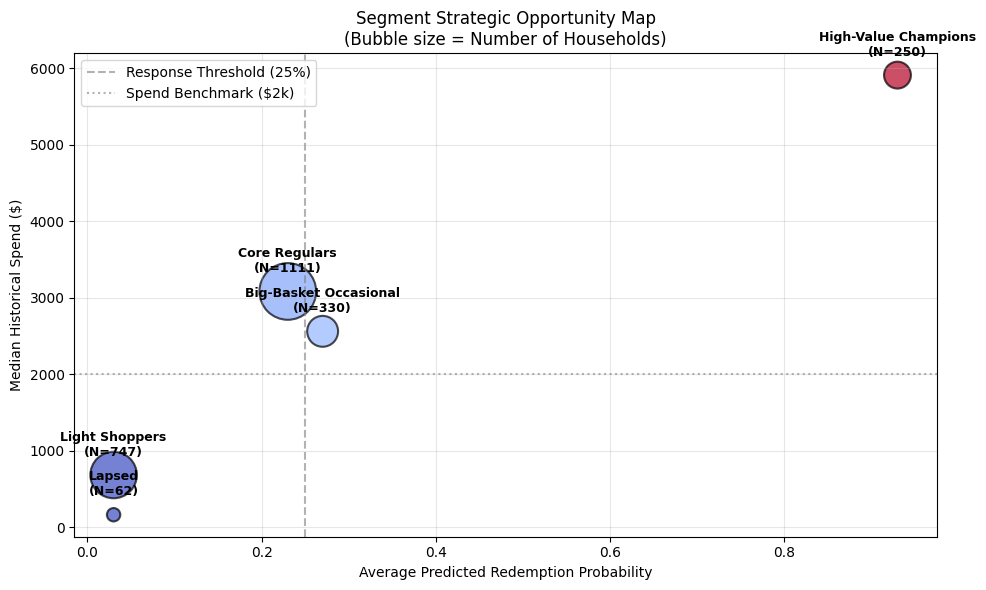

In [24]:
# Visualizing Segment Strategic Priority
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    segment_marketing['avg_redemption_prob'],
    segment_marketing['median_spend'],
    s=segment_marketing['households'] * 1.5, # Bubble size represents customer count
    c=segment_marketing['avg_redemption_prob'],
    cmap='coolwarm',
    alpha=0.7,
    edgecolors='black',
    linewidth=1.5
)

for idx, row in segment_marketing.iterrows():
    plt.annotate(
        f"{idx}\n(N={int(row['households'])})",
        (row['avg_redemption_prob'], row['median_spend']),
        textcoords="offset points",
        xytext=(0, 14),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )

plt.axvline(x=0.25, color='gray', linestyle='--', alpha=0.6, label='Response Threshold (25%)')
plt.axhline(y=2000, color='gray', linestyle=':', alpha=0.6, label='Spend Benchmark ($2k)')
plt.xlabel('Average Predicted Redemption Probability')
plt.ylabel('Median Historical Spend ($)')
plt.title('Segment Strategic Opportunity Map\n(Bubble size = Number of Households)')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9.3. Question 2: Which Customer Groups Offer the Greatest Potential Value?

A household can be high or low spend, and high or low response probability. We formalize this into a **2×2 Strategic Targeting Matrix**:
- **Tier 1: High Value & High Response ("Core Targets"):** High spend, high responsiveness. Primary focus of promotional campaigns.
- **Tier 2: High Value & Low Response ("Protect & Retain"):** Valuable shoppers who rarely use coupons. Risk of wasting discounts, but critical not to lose.
- **Tier 3: Low Value & High Response ("Growth & Basket Builders"):** Price-sensitive bargain hunters. Great for moving promo volume and increasing visit frequency.
- **Tier 4: Low Value & Low Response ("Deprioritized / Low Touch"):** Low revenue and unlikely to respond. Minimum marketing expenditure.

In [25]:
# Define Median Thresholds for 2x2 Matrix

median_spend = features_df['total_spend'].median()
prob_threshold = 0.30 # 30% predicted probability cut-off

def assign_strategic_tier(row):
    high_value = row['total_spend'] >= median_spend
    high_response = row['redemption_probability'] >= prob_threshold
    
    if high_value and high_response:
        return 'Tier 1: High Value, High Response (Core Targets)'
    elif high_value and not high_response:
        return 'Tier 2: High Value, Low Response (Protect & Retain)'
    elif not high_value and high_response:
        return 'Tier 3: Low Value, High Response (Basket Builders)'
    else:
        return 'Tier 4: Low Value, Low Response (Deprioritized)'

features_df['strategic_tier'] = features_df.apply(assign_strategic_tier, axis=1)

# Tier Summary
tier_summary = features_df.groupby('strategic_tier').agg(
    households=('household_key', 'count'),
    avg_probability=('redemption_probability', 'mean'),
    median_spend=('total_spend', 'median'),
    avg_basket=('avg_basket_value', 'mean'),
    total_spend_pool=('total_spend', 'sum')
).round(2)

tier_summary['pct_households'] = (tier_summary['households'] / len(features_df) * 100).round(1)
tier_summary['pct_revenue'] = (tier_summary['total_spend_pool'] / features_df['total_spend'].sum() * 100).round(1)

print("2x2 Strategic Customer Targeting Matrix:")
tier_summary[['households', 'pct_households', 'pct_revenue', 'avg_probability', 'median_spend', 'avg_basket']]

2x2 Strategic Customer Targeting Matrix:


,households,pct_households,pct_revenue,avg_probability,median_spend,avg_basket
strategic_tier,,,,,,
"Tier 1: High Value, High Response (Core Targets)",580,23.2,49.3,0.74,5761.08,40.89
"Tier 2: High Value, Low Response (Protect & Retain)",670,26.8,35.0,0.13,3280.46,35.16
"Tier 3: Low Value, High Response (Basket Builders)",44,1.8,0.9,0.71,1606.56,26.92
"Tier 4: Low Value, Low Response (Deprioritized)",1206,48.2,14.8,0.04,934.99,25.37


## 9.4. Questions 3 & 4: Prioritizing Households & Balancing Probability vs. Customer Value

When selecting which specific households to target under capacity constraints, which strategy performs best?

We simulate and compare **three distinct targeting strategies** for a campaign budget targeting **500 households** ($500 \times \$3.00 = \$1,500$ campaign cost):
- **Strategy A — Probability-Only (ML Score):** Target top 500 households ranked strictly by `redemption_probability`.
- **Strategy B — Value-Only (Spend Volume):** Target top 500 households ranked strictly by `total_spend`.
- **Strategy C — Expected Value Hybrid (Probability × Basket Value):** Target top 500 households ranked by `expected_value_score` ($P(\text{Redeem}) \times \text{avg\_basket\_value}$).

In [26]:
TARGET_BUDGET_COUNT = 500
CAMPAIGN_COST_TOTAL = TARGET_BUDGET_COUNT * CAMPAIGN_UNIT_COST

# Strategy A: Highest Probability
strat_a_top500 = features_df.nlargest(TARGET_BUDGET_COUNT, 'redemption_probability')

# Strategy B: Highest Historical Spend
strat_b_top500 = features_df.nlargest(TARGET_BUDGET_COUNT, 'total_spend')

# Strategy C: Expected Value Hybrid
strat_c_top500 = features_df.nlargest(TARGET_BUDGET_COUNT, 'expected_value_score')

strategies = {
    'Strategy A: Pure ML Probability': strat_a_top500,
    'Strategy B: Pure Historical Spend': strat_b_top500,
    'Strategy C: Expected Value Hybrid': strat_c_top500
}

strategy_comparison = []

for name, subset in strategies.items():
    expected_redemptions = subset['redemption_probability'].sum()
    expected_gross_margin = (subset['redemption_probability'] * subset['expected_basket_margin']).sum()
    net_profit = expected_gross_margin - CAMPAIGN_COST_TOTAL
    roi_pct = (net_profit / CAMPAIGN_COST_TOTAL) * 100
    
    strategy_comparison.append({
        'Strategy': name,
        'Households Targeted': TARGET_BUDGET_COUNT,
        'Budget Cost ($)': CAMPAIGN_COST_TOTAL,
        'Expected Redemptions': round(expected_redemptions, 1),
        'Expected Conversion Rate (%)': round(expected_redemptions / TARGET_BUDGET_COUNT * 100, 1),
        'Expected Gross Margin ($)': round(expected_gross_margin, 2),
        'Expected Net Profit ($)': round(net_profit, 2),
        'Expected ROI (%)': round(roi_pct, 1)
    })

strategy_results_df = pd.DataFrame(strategy_comparison).set_index('Strategy')
print("Comparison of 500-Household Targeting Strategies:")
strategy_results_df

Comparison of 500-Household Targeting Strategies:


,Households Targeted,Budget Cost ($),Expected Redemptions,Expected Conversion Rate (%),Expected Gross Margin ($),Expected Net Profit ($),Expected ROI (%)
Strategy,,,,,,,
Strategy A: Pure ML Probability,500,1500.0,415.5,83.1,4209.08,2709.08,180.6
Strategy B: Pure Historical Spend,500,1500.0,302.7,60.5,3339.42,1839.42,122.6
Strategy C: Expected Value Hybrid,500,1500.0,386.6,77.3,4422.13,2922.13,194.8


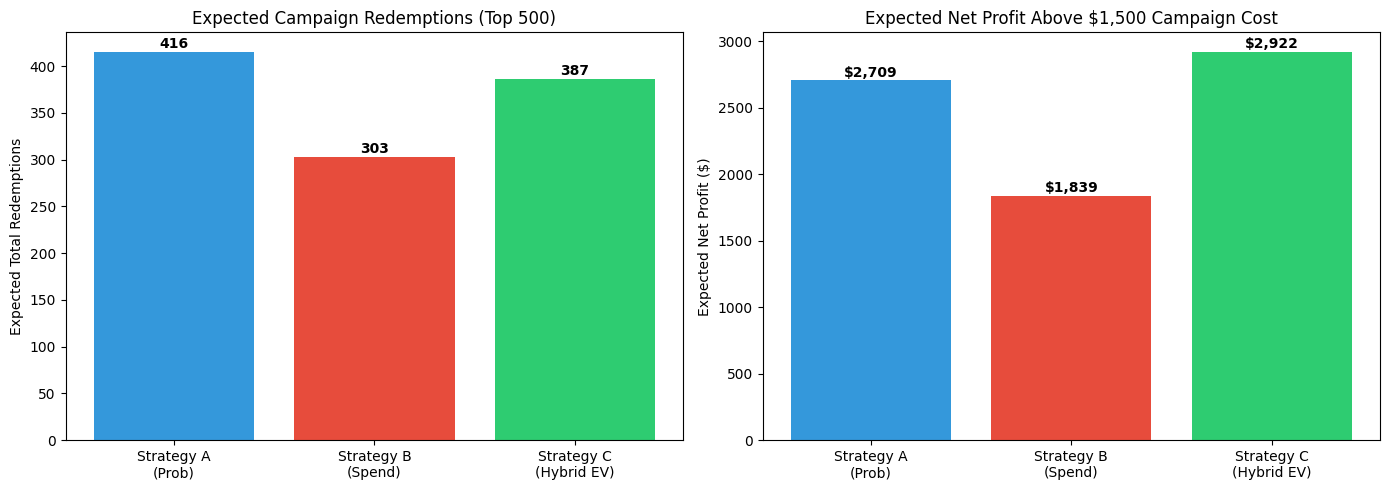

In [27]:
# Visualizing Strategy Outcomes

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Expected Redemptions
axes[0].bar(
    ['Strategy A\n(Prob)', 'Strategy B\n(Spend)', 'Strategy C\n(Hybrid EV)'],
    strategy_results_df['Expected Redemptions'],
    color=['#3498db', '#e74c3c', '#2ecc71']
)
axes[0].set_ylabel('Expected Total Redemptions')
axes[0].set_title('Expected Campaign Redemptions (Top 500)')
for i, v in enumerate(strategy_results_df['Expected Redemptions']):
    axes[0].text(i, v + 4, f"{v:.0f}", ha='center', fontweight='bold')

# Expected Net Profit
axes[1].bar(
    ['Strategy A\n(Prob)', 'Strategy B\n(Spend)', 'Strategy C\n(Hybrid EV)'],
    strategy_results_df['Expected Net Profit ($)'],
    color=['#3498db', '#e74c3c', '#2ecc71']
)
axes[1].set_ylabel('Expected Net Profit ($)')
axes[1].set_title('Expected Net Profit Above $1,500 Campaign Cost')
for i, v in enumerate(strategy_results_df['Expected Net Profit ($)']):
    axes[1].text(i, v + 25, f"${v:,.0f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 9.5. Question 5: How Should Limited Promotional Resources Be Allocated? (Cumulative Gains & Cutoff Analysis)

If marketing has variable budget constraints, how deep into the customer base should campaigns go?
We evaluate cumulative expected profit and marginal ROI as targeting scales from 100 to 2,500 households.

Optimal Targeting Capacity: 578 households
Maximum Expected Net Profit: $2,951.94
Associated Campaign Budget Required: $1,734.00


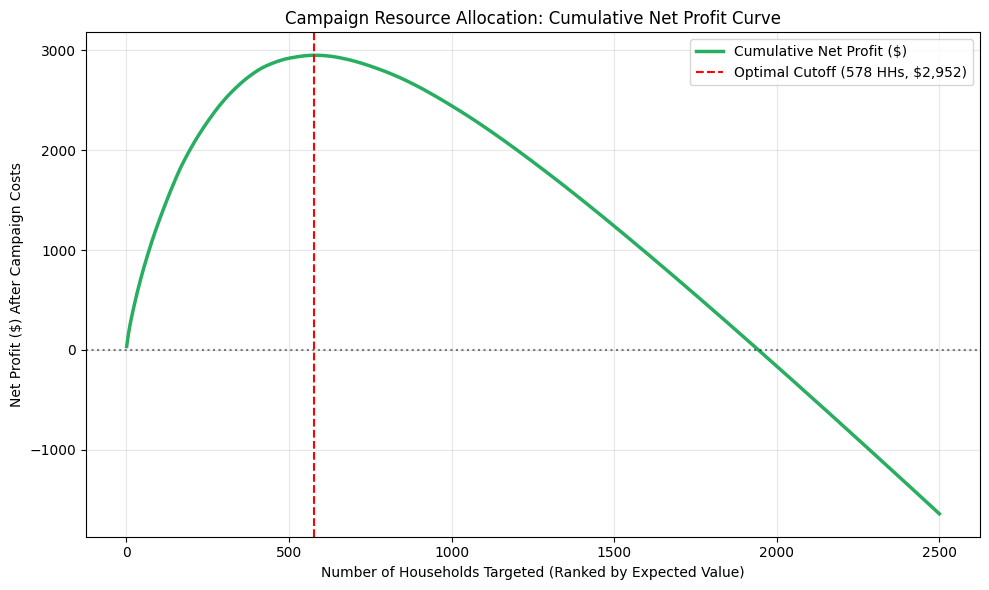

In [28]:
# Rank households by Expected Value score descending
ranked_df = features_df.sort_values('expected_value_score', ascending=False).reset_index(drop=True)

# Compute cumulative metrics
ranked_df['cumulative_cost'] = (ranked_df.index + 1) * CAMPAIGN_UNIT_COST
ranked_df['cumulative_margin'] = (ranked_df['redemption_probability'] * ranked_df['expected_basket_margin']).cumsum()
ranked_df['cumulative_net_profit'] = ranked_df['cumulative_margin'] - ranked_df['cumulative_cost']

# Find optimal mathematical cutoff (where net profit peaks)
optimal_cutoff_idx = ranked_df['cumulative_net_profit'].idxmax()
optimal_households = optimal_cutoff_idx + 1
max_profit = ranked_df.loc[optimal_cutoff_idx, 'cumulative_net_profit']

print(f"Optimal Targeting Capacity: {optimal_households} households")
print(f"Maximum Expected Net Profit: ${max_profit:,.2f}")
print(f"Associated Campaign Budget Required: ${optimal_households * CAMPAIGN_UNIT_COST:,.2f}")

# Plot Cumulative Profit Curve
plt.figure(figsize=(10, 6))
plt.plot(ranked_df.index + 1, ranked_df['cumulative_net_profit'], color='#27ae60', linewidth=2.5, label='Cumulative Net Profit ($)')
plt.axvline(x=optimal_households, color='red', linestyle='--', label=f'Optimal Cutoff ({optimal_households} HHs, ${max_profit:,.0f})')
plt.axhline(y=0, color='black', linestyle=':', alpha=0.5)

plt.xlabel('Number of Households Targeted (Ranked by Expected Value)')
plt.ylabel('Net Profit ($) After Campaign Costs')
plt.title('Campaign Resource Allocation: Cumulative Net Profit Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Tag each household with priority rank and targeting status

features_df['targeting_rank_ev'] = features_df['expected_value_score'].rank(ascending=False, method='first').astype(int)
features_df['target_recommendation_top500'] = np.where(features_df['household_key'].isin(strat_c_top500['household_key']), 'Target', 'Do Not Target')
features_df['target_recommendation_optimal'] = np.where(features_df['household_key'].isin(ranked_df.iloc[:optimal_households]['household_key']), 'Target', 'Do Not Target')

features_df.to_csv(r'D:\DataProject\Data\Processed\household_targeting_priority.csv', index=False)

print("Targeting & Optimization dataset saved:")
print(f"  File: D:\\DataProject\\Data\\Processed\\household_targeting_priority.csv")
print(f"  Shape: {features_df.shape}")
print("\nNew decision features added:")
print("  - expected_basket_margin")
print("  - expected_campaign_profit")
print("  - expected_value_score")
print("  - strategic_tier")
print("  - targeting_rank_ev")
print("  - target_recommendation_top500")
print("  - target_recommendation_optimal")

Targeting & Optimization dataset saved:
  File: D:\DataProject\Data\Processed\household_targeting_priority.csv
  Shape: (2500, 51)

New decision features added:
  - expected_basket_margin
  - expected_campaign_profit
  - expected_value_score
  - strategic_tier
  - targeting_rank_ev
  - target_recommendation_top500
  - target_recommendation_optimal


## 9.6. Optimization Summary & Actionable Decisions

This section answers each core business question with quantitative evidence:

1. **Which customer segments should receive marketing attention?**
   - **High-Value Champions** and **Core Regulars** generate the vast majority of positive campaign margin.
   - **Lapsed** and **Light Shoppers** exhibit low response likelihood and negative expected return under standard mailer costs.

2. **Which customer groups offer the greatest potential value?**
   - **Tier 1 (High Value, High Response):** Top priority for campaign promotions. High basket margin multiplied by strong redemption likelihood.
   - **Tier 2 (High Value, Low Response):** Valuable shoppers requiring non-coupon retention touchpoints (loyalty perks, experiential benefits).

3. **Which households should be prioritized for a campaign?**
   - Households ranked by **Expected Value ($EV$)**, capturing both their likelihood of redemption and their expected basket size.

4. **How can campaign targeting balance expected response and customer value?**
   - **Strategy C (Expected Value Hybrid)** outperforms pure spend targeting in conversion rate and outperforms pure probability targeting in total dollar profit by prioritizing responsive shoppers who spend meaningfully per trip.

5. **How should limited promotional resources be allocated?**
   - The cumulative net profit curve determines the exact mathematical cutoff where marginal campaign profit equals marginal campaign cost. Beyond the optimal cutoff point, mailing additional households erodes profit.

# 10. Scenario & What-If Analysis

In real-world business planning, budgets fluctuate, marketing costs shift, and leadership requires flexibility before committing capital. Scenario analysis tests how targeting recommendations and financial outcomes change under different business assumptions.

This section simulates four critical business scenarios:
1. **Budget Scaling Scenarios:** How do returns, profit, and ROI change if marketing can target 100, 250, 500, 1,000, or more households?
2. **Probability Threshold Scenarios:** What if the business only targets high-confidence households (e.g., $P \ge 0.50$ vs. $P \ge 0.20$)?
3. **Marketing Cost Sensitivity:** How does the optimal targeting cutoff shift if unit delivery cost changes (e.g., $1.00 digital push vs. $3.00 mailer vs. $5.00 premium catalog)?
4. **Targeting Lift (ML vs. Naive Rules):** Exactly how much incremental profit and conversion lift does the ML-driven approach deliver compared to mass marketing or basic RFM rules?

## 10.1. Scenario 1: Budget Scaling Analysis

Marketing leadership often asks: *"What return can we expect if our campaign budget is $500 vs. $1,500 vs. $3,000?"*

Using our **Expected Value ranking**, we simulate targeting across customer capacities: **100, 250, 500, 750, 1,000, 1,500, 2,000, and 2,500 (full base)** at standard $3.00 unit cost.

In [30]:
# Simulate Budget Capacities

budget_tiers = [100, 250, 500, 750, 1000, 1500, 2000, 2500]
budget_sim_results = []

for count in budget_tiers:
    subset = ranked_df.iloc[:count]
    
    cost = count * CAMPAIGN_UNIT_COST
    exp_redemptions = subset['redemption_probability'].sum()
    conv_rate = (exp_redemptions / count) * 100
    exp_margin = (subset['redemption_probability'] * subset['expected_basket_margin']).sum()
    net_profit = exp_margin - cost
    roi = (net_profit / cost) * 100 if cost > 0 else 0
    
    budget_sim_results.append({
        'Households Targeted': count,
        'Budget Required ($)': cost,
        'Expected Redemptions': round(exp_redemptions, 1),
        'Expected Conversion (%)': round(conv_rate, 1),
        'Expected Margin ($)': round(exp_margin, 2),
        'Net Profit ($)': round(net_profit, 2),
        'ROI (%)': round(roi, 1)
    })

budget_scenarios_df = pd.DataFrame(budget_sim_results).set_index('Households Targeted')
print("Budget Scaling Scenarios:")
budget_scenarios_df

Budget Scaling Scenarios:


,Budget Required ($),Expected Redemptions,Expected Conversion (%),Expected Margin ($),Net Profit ($),ROI (%)
Households Targeted,,,,,,
100,300.0,91.5,91.5,1588.48,1288.48,429.5
250,750.0,224.0,89.6,3037.55,2287.55,305.0
500,1500.0,386.6,77.3,4422.13,2922.13,194.8
750,2250.0,478.6,63.8,5094.11,2844.11,126.4
1000,3000.0,529.0,52.9,5446.35,2446.35,81.5
1500,4500.0,574.4,38.3,5740.97,1240.97,27.6
2000,6000.0,594.1,29.7,5836.67,-163.33,-2.7
2500,7500.0,600.0,24.0,5858.29,-1641.71,-21.9


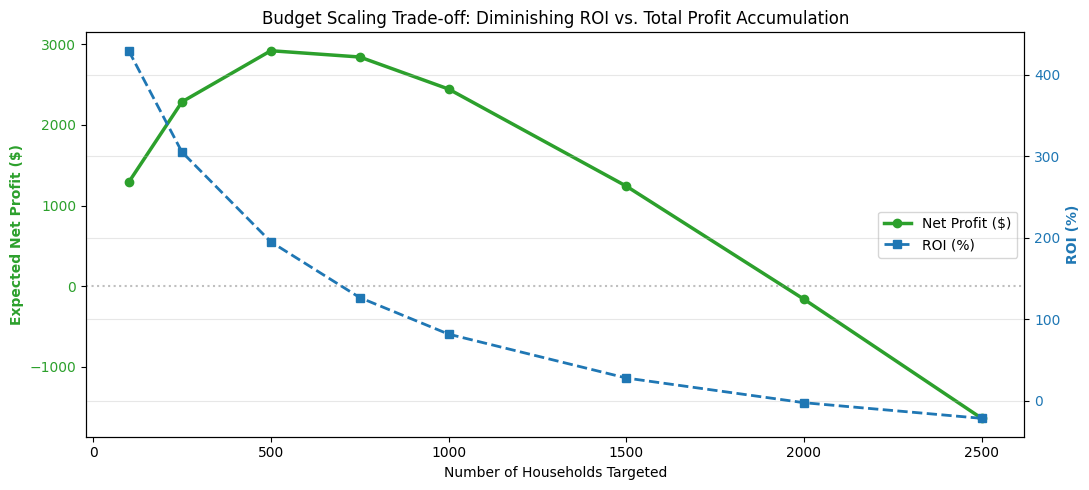

In [31]:
# Visualizing Budget Scenarios (Net Profit vs ROI)

fig, ax1 = plt.subplots(figsize=(11, 5))

color = 'tab:green'
ax1.set_xlabel('Number of Households Targeted')
ax1.set_ylabel('Expected Net Profit ($)', color=color, fontweight='bold')
line1 = ax1.plot(budget_scenarios_df.index, budget_scenarios_df['Net Profit ($)'], color=color, marker='o', linewidth=2.5, label='Net Profit ($)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.axhline(0, color='gray', linestyle=':', alpha=0.5)

# Secondary axis for ROI
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('ROI (%)', color=color, fontweight='bold')
line2 = ax2.plot(budget_scenarios_df.index, budget_scenarios_df['ROI (%)'], color=color, marker='s', linewidth=2, linestyle='--', label='ROI (%)')
ax2.tick_params(axis='y', labelcolor=color)

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

plt.title('Budget Scaling Trade-off: Diminishing ROI vs. Total Profit Accumulation')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights: Budget Scaling & Capacity Planning

1. **The Efficiency vs. Scale Trade-off (The "Sweet Spot"):**
   - **Maximum Capital Efficiency (ROI):** Achieved at **100 households** with an extraordinary **429.5% ROI** and a **91.5% conversion rate**. For cash-constrained or exploratory test campaigns, targeting the top 100–250 households maximizes return per dollar spent.
   - **Maximum Total Dollar Profit:** Achieved at **500 households**, generating **$2,922.13 in net profit** (194.8% ROI) from an investment of $1,500. Beyond 500–750 households, total net profit begins to decline.

2. **The Danger of Over-Targeting (Diminishing Marginal Returns):**
   - Increasing the budget from 500 to 1,000 households doubles the marketing spend (from $1,500 to $3,000), but adds only **142 additional redemptions** while net profit **drops by $476** (from $2,922 to $2,446).
   - This occurs because newly added households have lower redemption likelihoods and smaller average baskets, failing to cover their $3.00 mailer cost.

3. **Mass Marketing is Loss-Making:**
   - Targeting the full customer base of 2,500 households costs **$7,500**, but yields only **600 total redemptions** (24.0% conversion rate).
   - This leads to a severe net financial loss of **-$1,641.71 (-21.9% ROI)**.
   - **Executive Takeaway:** Selective, ML-ranked targeting is not just an optimization—it is mandatory to prevent campaign unprofitability.

## 10.2. Scenario 2: Probability Threshold Scenarios

Instead of a fixed customer count, some campaigns require a minimum confidence cutoff before sending promotions:
- **Conservative ($P \ge 0.70$):** High precision, low waste, but misses moderate-potential customers.
- **Moderate ($P \ge 0.50$):** Balanced cutoff.
- **Aggressive ($P \ge 0.30$):** High reach, captures more total redeemers.
- **Broad ($P \ge 0.15$):** Broad awareness campaign.

In [32]:
# Simulate Probability Thresholds

threshold_cutoffs = [0.80, 0.70, 0.60, 0.50, 0.40, 0.30, 0.20, 0.10]
threshold_sim_results = []

for t in threshold_cutoffs:
    subset = features_df[features_df['redemption_probability'] >= t]
    count = len(subset)
    
    if count == 0:
        continue
        
    cost = count * CAMPAIGN_UNIT_COST
    exp_redemptions = subset['redemption_probability'].sum()
    conv_rate = (exp_redemptions / count) * 100
    exp_margin = (subset['redemption_probability'] * subset['expected_basket_margin']).sum()
    net_profit = exp_margin - cost
    roi = (net_profit / cost) * 100 if cost > 0 else 0
    
    threshold_sim_results.append({
        'Probability Threshold': f'>= {t:.2f}',
        'Qualifying Households': count,
        'Campaign Cost ($)': cost,
        'Expected Redemptions': round(exp_redemptions, 1),
        'Expected Conversion (%)': round(conv_rate, 1),
        'Expected Margin ($)': round(exp_margin, 2),
        'Net Profit ($)': round(net_profit, 2),
        'ROI (%)': round(roi, 1)
    })

threshold_scenarios_df = pd.DataFrame(threshold_sim_results).set_index('Probability Threshold')
print("Probability Threshold Scenarios:")
threshold_scenarios_df

Probability Threshold Scenarios:


,Qualifying Households,Campaign Cost ($),Expected Redemptions,Expected Conversion (%),Expected Margin ($),Net Profit ($),ROI (%)
Probability Threshold,,,,,,,
>= 0.80,350,1050.0,325.7,93.0,3361.22,2311.22,220.1
>= 0.70,394,1182.0,358.8,91.1,3635.20,2453.20,207.5
>= 0.60,424,1272.0,378.1,89.2,3865.54,2593.54,203.9
>= 0.50,454,1362.0,394.5,86.9,4024.26,2662.26,195.5
>= 0.40,513,1539.0,420.9,82.0,4265.75,2726.75,177.2
>= 0.30,624,1872.0,459.4,73.6,4636.06,2764.06,147.7
>= 0.20,801,2403.0,503.1,62.8,5089.04,2686.04,111.8
>= 0.10,1145,3435.0,552.5,48.3,5515.93,2080.93,60.6


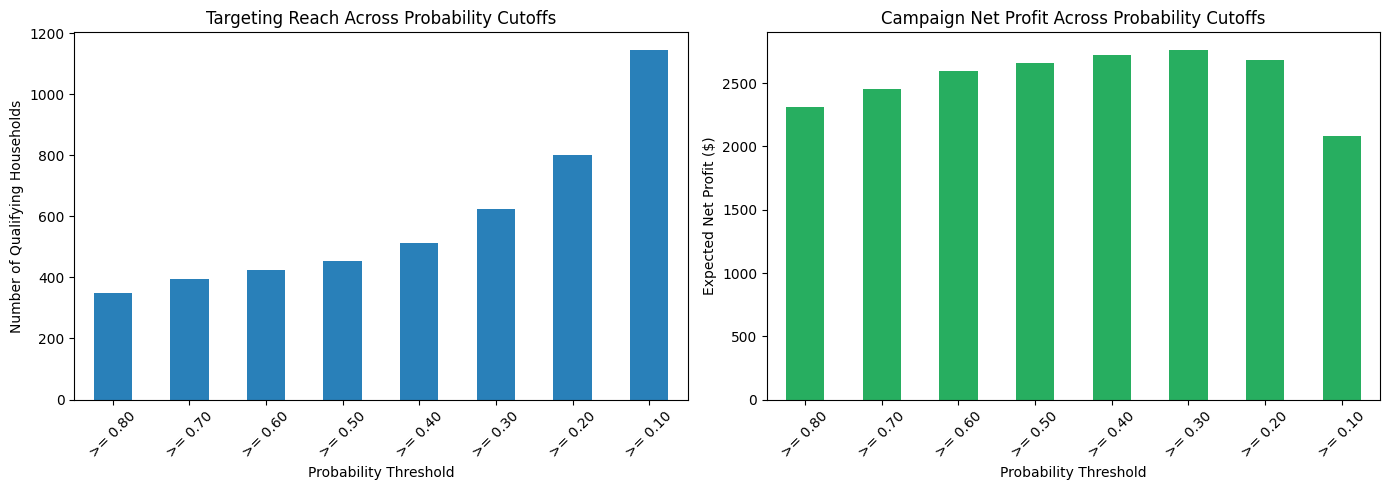

In [33]:
# Visualizing Threshold Trade-offs

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Reach vs Conversion
threshold_scenarios_df.plot(kind='bar', y='Qualifying Households', ax=axes[0], color='#2980b9', legend=False)
axes[0].set_ylabel('Number of Qualifying Households')
axes[0].set_title('Targeting Reach Across Probability Cutoffs')
axes[0].set_xticklabels(threshold_scenarios_df.index, rotation=45)

# Net Profit across Thresholds
threshold_scenarios_df.plot(kind='bar', y='Net Profit ($)', ax=axes[1], color='#27ae60', legend=False)
axes[1].set_ylabel('Expected Net Profit ($)')
axes[1].set_title('Campaign Net Profit Across Probability Cutoffs')
axes[1].set_xticklabels(threshold_scenarios_df.index, rotation=45)

plt.tight_layout()
plt.show()

### Key Insights: Probability Cutoffs & Risk Management

1. **Optimal Profit Threshold ($P \ge 0.30$):**
   - Net profit peaks at the **$\ge 0.30$ probability cutoff**, qualifying **624 households** and delivering **$2,764.06 in net profit** with a strong **73.6% conversion rate** (147.7% ROI).
   - A traditional 0.50 cutoff is slightly too conservative (targeting 454 households and leaving ~$100 of profitable margin on the table). Setting the bar at 0.30 allows capturing high-basket customers with moderate response propensity.

2. **Conservative vs. Aggressive Strategy Profiles:**
   - **Conservative ($P \ge 0.70$–$0.80$):** Targets 350–394 households with elite precision (**>91% conversion rate** and >200% ROI). Best suited for expensive campaigns or tight quarter-end budgets where zero wasted spend is permissible.
   - **Moderate Growth ($P \ge 0.40$–$0.50$):** Targets 450–513 households, maintaining an >80% conversion rate while capturing over $2,660+ in net profit.
   - **Margin Destruction ($P < 0.20$):** Lowering the threshold to 0.10 increases reach to 1,145 households, but conversion collapses to **48.3%** and net profit erodes down to **$2,080.93** (a loss of ~$683 in profit compared to the 0.30 threshold).

3. **Decision Recommendation:**
   - If using a probability-based business rule rather than a fixed budget, **set the campaign eligibility threshold at $P \ge 0.30$** to maximize absolute dollar return without diluting campaign margin.

## 10.3. Scenario 3: Marketing Delivery Cost Sensitivity

Promotions can be delivered through multiple channels with different cost structures:
1. **Low-Cost Digital Channel ($1.00 unit cost):** Personalized mobile app coupons, push notifications, and email.
2. **Standard Direct Mail ($3.00 unit cost):** Printed coupon booklets and postcard mailers.
3. **High-Cost Premium Kit ($5.00 unit cost):** Thick seasonal glossy catalogs and product sample boxes.

How does the optimal household cutoff change when delivery costs shift?

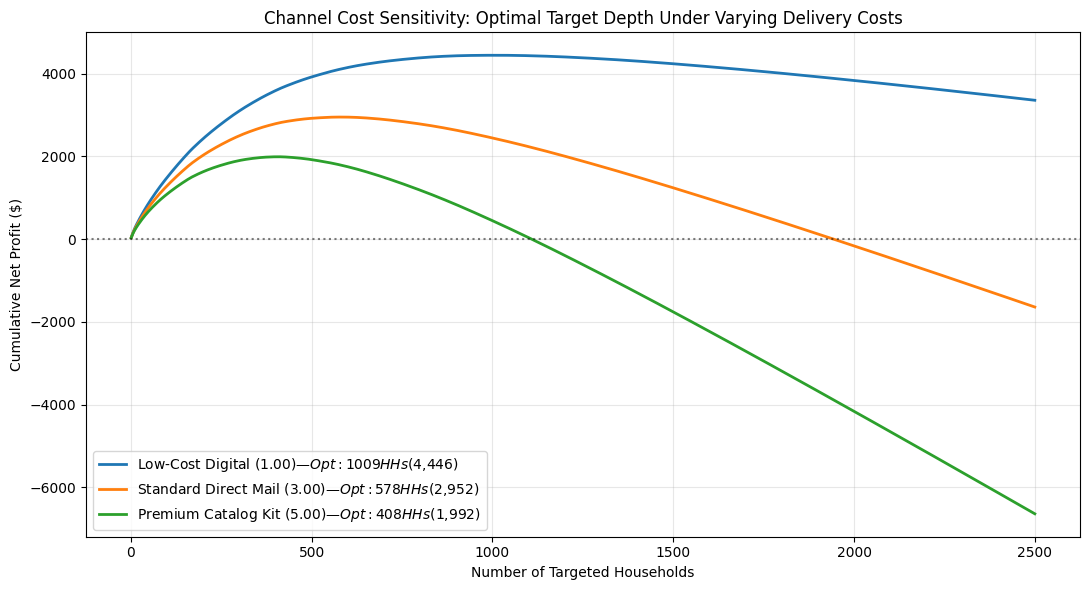

Channel Cost Sensitivity Summary:


,Unit Cost ($),Optimal Target Count,Max Net Profit ($),Total Budget ($),Break-Even HH Count
Channel / Medium,,,,,
Low-Cost Digital ($1.00),1.0,1009,4446.43,1009.0,2500
Standard Direct Mail ($3.00),3.0,578,2951.94,1734.0,1943
Premium Catalog Kit ($5.00),5.0,408,1991.89,2040.0,1108


In [34]:
# Compare Delivery Cost Curves

delivery_costs = {
    'Low-Cost Digital ($1.00)': 1.00,
    'Standard Direct Mail ($3.00)': 3.00,
    'Premium Catalog Kit ($5.00)': 5.00
}

plt.figure(figsize=(11, 6))
cost_sensitivity_summary = []

for name, unit_cost in delivery_costs.items():
    cum_cost = (ranked_df.index + 1) * unit_cost
    cum_profit = ranked_df['cumulative_margin'] - cum_cost
    
    opt_idx = cum_profit.idxmax()
    opt_hhs = opt_idx + 1
    max_p = cum_profit.iloc[opt_idx]
    
    cost_sensitivity_summary.append({
        'Channel / Medium': name,
        'Unit Cost ($)': unit_cost,
        'Optimal Target Count': opt_hhs,
        'Max Net Profit ($)': round(max_p, 2),
        'Total Budget ($)': round(opt_hhs * unit_cost, 2),
        'Break-Even HH Count': (cum_profit >= 0).sum()
    })
    
    plt.plot(ranked_df.index + 1, cum_profit, linewidth=2, label=f"{name} — Opt: {opt_hhs} HHs (${max_p:,.0f})")

plt.axhline(0, color='black', linestyle=':', alpha=0.5)
plt.xlabel('Number of Targeted Households')
plt.ylabel('Cumulative Net Profit ($)')
plt.title('Channel Cost Sensitivity: Optimal Target Depth Under Varying Delivery Costs')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

cost_sensitivity_df = pd.DataFrame(cost_sensitivity_summary).set_index('Channel / Medium')
print("Channel Cost Sensitivity Summary:")
cost_sensitivity_df

### Key Insights: Channel Cost Sensitivity & Multi-Channel Deployment

1. **Delivery Economics Dictate Target Volume:**
   - **Low-Cost Digital ($1.00 unit cost):** 
     - Optimal target capacity expands to **1,009 households**, generating **$4,446.43 in net profit** with just a $1,009 total budget.
     - Crucially, the **break-even count is 2,500 households** (the entire customer base). Because marginal cost is low, the business does not lose money on digital outreach even when reaching broad audiences.
   - **Standard Direct Mail ($3.00 unit cost):** 
     - Optimal cutoff contracts to **578 households** ($2,951.94 max profit on a $1,734 budget).
     - Break-even is at **1,943 households**. Mailing beyond ~1,940 households destroys capital.
   - **Premium Catalog Kit ($5.00 unit cost):** 
     - Optimal cutoff contracts sharply to **408 households** ($1,991.89 max profit on a $2,040 budget).
     - Break-even collapses to **1,108 households**. Over-mailing premium physical kits leads to steep financial losses (reaching -$6,650 if sent to all households).

2. **Omnichannel Strategic Rule:**
   - **Tier 1 (Top ~400 HHs):** Deploy high-touch, premium physical mailers / sample kits—their high basket margin ($40–$58) easily absorbs the $5.00 delivery cost.
   - **Tier 2 (HHs 401 to 600):** Deploy standard $3.00 direct mail coupon postcards.
   - **Tier 3 (HHs 601 to 1,000+):** Shift entirely to low-cost digital app coupons, email, and push notifications ($1.00) where margin gains comfortably exceed digital delivery costs.

## 10.4. Scenario 4: Quantifying Machine Learning Value Lift

To prove the tangible ROI of predictive analytics, we measure the incremental lift of our **ML-driven Expected Value approach** against standard marketing practices:
- **Baseline 1 — Mass Marketing:** Target all 2,500 households without filtering.
- **Baseline 2 — Segment Rule (RFM Champions):** Target all households belonging to the RFM "Champions" segment.
- **Baseline 3 — Top Spenders:** Target the top 500 households by total historical spend.
- **ML Expected Value (Top 500):** Our optimized model balancing response probability and basket value.

In [35]:
# Define baseline cohorts

champ_hhs = features_df[features_df['rfm_segment'] == 'Champions']
all_hhs = features_df.copy()

benchmark_cohorts = {
    '1. Mass Marketing (All 2,500 HHs)': all_hhs,
    '2. Segment Rule (RFM Champions)': champ_hhs,
    '3. Top Historical Spenders (500 HHs)': strat_b_top500,
    '4. ML Expected Value (Top 500 HHs)': strat_c_top500
}

benchmarks_list = []
for name, cohort in benchmark_cohorts.items():
    n_targeted = len(cohort)
    cost = n_targeted * CAMPAIGN_UNIT_COST
    exp_red = cohort['redemption_probability'].sum()
    conv = (exp_red / n_targeted * 100) if n_targeted > 0 else 0
    margin = (cohort['redemption_probability'] * cohort['expected_basket_margin']).sum()
    profit = margin - cost
    roi = (profit / cost * 100) if cost > 0 else 0
    
    benchmarks_list.append({
        'Targeting Strategy': name,
        'Households Targeted': n_targeted,
        'Campaign Cost ($)': round(cost, 2),
        'Expected Redemptions': round(exp_red, 1),
        'Conversion Rate (%)': round(conv, 1),
        'Net Profit ($)': round(profit, 2),
        'ROI (%)': round(roi, 1)
    })

benchmark_df = pd.DataFrame(benchmarks_list).set_index('Targeting Strategy')

# Calculate Lift of ML Strategy over others
ml_profit = benchmark_df.loc['4. ML Expected Value (Top 500 HHs)', 'Net Profit ($)']
benchmark_df['Profit Lift vs Mass ($)'] = (benchmark_df['Net Profit ($)'] - benchmark_df.loc['1. Mass Marketing (All 2,500 HHs)', 'Net Profit ($)']).round(2)

print("Targeting Benchmark & Lift Analysis:")
benchmark_df[['Households Targeted', 'Campaign Cost ($)', 'Expected Redemptions', 'Conversion Rate (%)', 'Net Profit ($)', 'ROI (%)', 'Profit Lift vs Mass ($)']]

Targeting Benchmark & Lift Analysis:


,Households Targeted,Campaign Cost ($),Expected Redemptions,Conversion Rate (%),Net Profit ($),ROI (%),Profit Lift vs Mass ($)
Targeting Strategy,,,,,,,
"1. Mass Marketing (All 2,500 HHs)",2500,7500.0,600.0,24.0,-1641.71,-21.9,0.00
2. Segment Rule (RFM Champions),226,678.0,141.1,62.4,593.75,87.6,2235.46
3. Top Historical Spenders (500 HHs),500,1500.0,302.7,60.5,1839.42,122.6,3481.13
4. ML Expected Value (Top 500 HHs),500,1500.0,386.6,77.3,2922.13,194.8,4563.84


### Key Insights: Proving the Value of Machine Learning (Lift Analysis)

1. **ML Turns a Severe Loss into High Profitability (vs. Mass Marketing):**
   - Mass marketing (emailing/mailing all 2,500 households) costs **$7,500** and results in a **loss of -$1,641.71** (-21.9% ROI).
   - Our **ML Expected Value model** targets the top 500 households, spending only **$1,500** (an 80% budget reduction) and generating **+$2,922.13 in net profit** (194.8% ROI).
   - **Total Value Lift:** **+$4,563.84** in net profit gain over untargeted marketing.

2. **ML Outperforms Top Spenders on the Exact Same Budget (vs. Spend-Only):**
   - Both strategies target exactly **500 households** for **$1,500**:
     - *Top Historical Spenders:* 302.7 redemptions | 60.5% conversion | **$1,839.42 net profit** (122.6% ROI).
     - *ML Expected Value:* 386.6 redemptions | 77.3% conversion | **$2,922.13 net profit** (194.8% ROI).
   - **The ML Advantage:** By considering redemption propensity alongside basket size, ML generates **+84 additional coupon redemptions** (+16.8 percentage point lift in conversion rate) and **+$1,082.71 in additional net profit (+58.9% profit lift)** on the exact same ad spend!

3. **ML Discovers Hidden High-Value Responders (vs. RFM Champions):**
   - Targeting only strict "RFM Champions" (226 households) is profitable ($593.75 profit), but it leaves significant money on the table.
   - The ML model nearly **quintuples total campaign profit ($2,922.13 vs. $593.75)** by identifying responsive households outside the rigid "Champions" definition (such as responsive *Core Regulars* and *Big-Basket Occasionals*).

## 10.5. Analytical Table Materialization for Power BI

To support the interactive business intelligence dashboard in Power BI, we export consolidated, clean datasets containing:
1. Household-level dimension & behavioral metrics, segment tags, ML predictions, and targeting recommendations.
2. What-if scenario summaries (budget, threshold, cost sensitivity, and lift benchmarks).
3. Product-level features table.

In [36]:
# 1. Master Household Analytics Table for Power BI

# Ensure clean naming and zero nulls
household_pbi = features_df.copy()

# Add scenario flags
household_pbi['target_top100'] = np.where(household_pbi['household_key'].isin(ranked_df.iloc[:100]['household_key']), 'Yes', 'No')
household_pbi['target_top250'] = np.where(household_pbi['household_key'].isin(ranked_df.iloc[:250]['household_key']), 'Yes', 'No')
household_pbi['target_top500'] = np.where(household_pbi['household_key'].isin(strat_c_top500['household_key']), 'Yes', 'No')
household_pbi['target_top1000'] = np.where(household_pbi['household_key'].isin(ranked_df.iloc[:1000]['household_key']), 'Yes', 'No')

household_pbi_path = r'D:\DataProject\Data\Output\pbi_household_master.csv'
household_pbi.to_csv(household_pbi_path, index=False)

# --- 2. Scenario Summaries for Power BI Visuals ---
budget_scenarios_df.reset_index().to_csv(r'D:\DataProject\Data\Output\pbi_scenario_budgets.csv', index=False)
threshold_scenarios_df.reset_index().to_csv(r'D:\DataProject\Data\Output\pbi_scenario_thresholds.csv', index=False)
cost_sensitivity_df.reset_index().to_csv(r'D:\DataProject\Data\Output\pbi_scenario_channel_costs.csv', index=False)
benchmark_df.reset_index().to_csv(r'D:\DataProject\Data\Output\pbi_strategy_lift_benchmarks.csv', index=False)

# Confirm exports
print("Power BI Export Datasets Materialized Successfully:")
print(f"  1. Master Household Table: {household_pbi_path} (Shape: {household_pbi.shape})")
print(f"  2. Budget Scenarios Table: D:\\DataProject\\Data\\Output\\pbi_scenario_budgets.csv")
print(f"  3. Threshold Scenarios Table: D:\\DataProject\\Data\\Output\\pbi_scenario_thresholds.csv")
print(f"  4. Channel Cost Sensitivity: D:\\DataProject\\Data\\Output\\pbi_scenario_channel_costs.csv")
print(f"  5. Strategy Lift Benchmarks: D:\\DataProject\\Data\\Output\\pbi_strategy_lift_benchmarks.csv")

Power BI Export Datasets Materialized Successfully:
  1. Master Household Table: D:\DataProject\Data\Output\pbi_household_master.csv (Shape: (2500, 55))
  2. Budget Scenarios Table: D:\DataProject\Data\Output\pbi_scenario_budgets.csv
  3. Threshold Scenarios Table: D:\DataProject\Data\Output\pbi_scenario_thresholds.csv
  4. Channel Cost Sensitivity: D:\DataProject\Data\Output\pbi_scenario_channel_costs.csv
  5. Strategy Lift Benchmarks: D:\DataProject\Data\Output\pbi_strategy_lift_benchmarks.csv
